# Airline Flight Delay Prediction

**Prepared by:**

| Student Name | Student ID |
|---|---|
| Reem Alwegdani | 2323653 |
| Shahad Banakher | 2305945 |
| Jory Alsufyani | 2306407 |
| Reem Alzahrani | 2307042 |
**Section:** DAR

## Project Overview

This project examines historical airline flight data to support the prediction of whether a flight will arrive delayed or on time. The dataset includes flight schedules, departure and arrival delays, flight duration, distance, and airline and airport information. This notebook focuses on the initial data exploration: examining the datasets, identifying missing values and attribute types, visualizing flight delays, and studying correlations between numerical attributes. The classification target and prediction model will be developed in a later phase.


# Airline Flight Delay Prediction

## 1. Dataset Loading

This project uses the 2015 US Flight Delays dataset from Kaggle. The dataset contains flight schedules, airline information, airport details, and flight delay records.

Three CSV files are used:

- **Flights:** Flight schedules, airport codes, distances, and delay information.
- **Airports:** Airport codes, names, and locations.
- **Airlines:** Airline codes and names.

The Flights dataset is used for prediction. The other two datasets provide additional information for understanding the data.

In [19]:
# Import libraries
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import kagglehub

from IPython.display import display

# Download the dataset
path = kagglehub.dataset_download("usdot/flight-delays")

# Load flight records
# Airport codes are read as strings because some records use numeric codes
flights = pd.read_csv(
    os.path.join(path, "flights.csv"),
    dtype={
        "ORIGIN_AIRPORT": "str",
        "DESTINATION_AIRPORT": "str"
    },
    low_memory=False
)

# Load airline and airport information
airlines = pd.read_csv(os.path.join(path, "airlines.csv"))
airports = pd.read_csv(os.path.join(path, "airports.csv"))

# Store the datasets for inspection
datasets = {
    "Flights": flights,
    "Airlines": airlines,
    "Airports": airports
}

# Display dataset dimensions
for name, data in datasets.items():
    print(f"{name}: {data.shape}")

Flights: (5819079, 31)
Airlines: (14, 2)
Airports: (322, 7)


## 2. Dataset Inspection

The datasets are inspected to understand their structure, data types, missing values, and duplicate records.

The first and last five rows are displayed to review the available attributes and sample values.

In [20]:
# Display the first and last five records of each dataset
for name, data in datasets.items():
    print(f"\nFirst 5 rows of {name}:")
    display(data.head())

    print(f"\nLast 5 rows of {name}:")
    display(data.tail())


First 5 rows of Flights:


,YEAR,MONTH,DAY,DAY_OF_WEEK,AIRLINE,FLIGHT_NUMBER,TAIL_NUMBER,ORIGIN_AIRPORT,DESTINATION_AIRPORT,SCHEDULED_DEPARTURE,...,ARRIVAL_TIME,ARRIVAL_DELAY,DIVERTED,CANCELLED,CANCELLATION_REASON,AIR_SYSTEM_DELAY,SECURITY_DELAY,AIRLINE_DELAY,LATE_AIRCRAFT_DELAY,WEATHER_DELAY
0,2015,1,1,4,AS,98,N407AS,ANC,SEA,5,...,408.0,-22.0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
1,2015,1,1,4,AA,2336,N3KUAA,LAX,PBI,10,...,741.0,-9.0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
2,2015,1,1,4,US,840,N171US,SFO,CLT,20,...,811.0,5.0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
3,2015,1,1,4,AA,258,N3HYAA,LAX,MIA,20,...,756.0,-9.0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
4,2015,1,1,4,AS,135,N527AS,SEA,ANC,25,...,259.0,-21.0,0,0,NaN,NaN,NaN,NaN,NaN,NaN



Last 5 rows of Flights:


,YEAR,MONTH,DAY,DAY_OF_WEEK,AIRLINE,FLIGHT_NUMBER,TAIL_NUMBER,ORIGIN_AIRPORT,DESTINATION_AIRPORT,SCHEDULED_DEPARTURE,...,ARRIVAL_TIME,ARRIVAL_DELAY,DIVERTED,CANCELLED,CANCELLATION_REASON,AIR_SYSTEM_DELAY,SECURITY_DELAY,AIRLINE_DELAY,LATE_AIRCRAFT_DELAY,WEATHER_DELAY
5819074,2015,12,31,4,B6,688,N657JB,LAX,BOS,2359,...,753.0,-26.0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
5819075,2015,12,31,4,B6,745,N828JB,JFK,PSE,2359,...,430.0,-16.0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
5819076,2015,12,31,4,B6,1503,N913JB,JFK,SJU,2359,...,432.0,-8.0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
5819077,2015,12,31,4,B6,333,N527JB,MCO,SJU,2359,...,330.0,-10.0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
5819078,2015,12,31,4,B6,839,N534JB,JFK,BQN,2359,...,442.0,2.0,0,0,NaN,NaN,NaN,NaN,NaN,NaN



First 5 rows of Airlines:


,IATA_CODE,AIRLINE
0,UA,United Air Lines Inc.
1,AA,American Airlines Inc.
2,US,US Airways Inc.
3,F9,Frontier Airlines Inc.
4,B6,JetBlue Airways


... (2 outputs left out)


First 5 rows of Airports:


,IATA_CODE,AIRPORT,CITY,STATE,COUNTRY,LATITUDE,LONGITUDE
0,ABE,Lehigh Valley International Airport,Allentown,PA,USA,40.65236,-75.44040
1,ABI,Abilene Regional Airport,Abilene,TX,USA,32.41132,-99.68190
2,ABQ,Albuquerque International Sunport,Albuquerque,NM,USA,35.04022,-106.60919
3,ABR,Aberdeen Regional Airport,Aberdeen,SD,USA,45.44906,-98.42183
4,ABY,Southwest Georgia Regional Airport,Albany,GA,USA,31.53552,-84.19447



Last 5 rows of Airports:


,IATA_CODE,AIRPORT,CITY,STATE,COUNTRY,LATITUDE,LONGITUDE
317,WRG,Wrangell Airport,Wrangell,AK,USA,56.48433,-132.36982
318,WYS,Westerly State Airport,West Yellowstone,MT,USA,44.68840,-111.11764
319,XNA,Northwest Arkansas Regional Airport,Fayetteville/Springdale/Rogers,AR,USA,36.28187,-94.30681
320,YAK,Yakutat Airport,Yakutat,AK,USA,59.50336,-139.66023
321,YUM,Yuma International Airport,Yuma,AZ,USA,32.65658,-114.60597


### 2a. Number of Instances and Attributes

The number of records and attributes is counted for each dataset.

Instances refer to rows, while attributes refer to columns.

In [21]:
# 2a. Number of instances and attributes
# Instances are rows, and attributes are columns.
for name, data in datasets.items():
    print(f"\n{name}")
    print("Number of instances:", data.shape[0])
    print("Number of attributes:", data.shape[1])


Flights
Number of instances: 5819079
Number of attributes: 31

Airlines
Number of instances: 14
Number of attributes: 2

Airports
Number of instances: 322
Number of attributes: 7


### 2b. Missing Values

Missing values are counted for each dataset and attribute.

This check helps identify columns that may require cleaning before analysis and model training.

In [22]:
# 2b. Missing values
for name, data in datasets.items():
    print(f"\n{name}")
    print("Total missing values:", data.isnull().sum().sum())
    print("\nMissing values per attribute:")
    display(data.isnull().sum().to_frame("Missing Values"))


Flights
Total missing values: 30465274

Missing values per attribute:


,Missing Values
YEAR,0
MONTH,0
DAY,0
DAY_OF_WEEK,0
AIRLINE,0
FLIGHT_NUMBER,0
TAIL_NUMBER,14721
ORIGIN_AIRPORT,0
DESTINATION_AIRPORT,0
SCHEDULED_DEPARTURE,0



Airlines
Total missing values: 0

Missing values per attribute:


,Missing Values
IATA_CODE,0
AIRLINE,0



Airports
Total missing values: 6

Missing values per attribute:


,Missing Values
IATA_CODE,0
AIRPORT,0
CITY,0
STATE,0
COUNTRY,0
LATITUDE,3
LONGITUDE,3


### 2c. Missing-Value Representation

Missing values may be stored as NaN or represented using text such as "unknown" or "?".

The datasets are checked for these representations.

In [23]:
# 2c. Missing-value representation
for name, data in datasets.items():
    print(f"\n{name}")
    print("NaN values:", data.isna().sum().sum())

    for col in data.select_dtypes(include=["object", "str"]).columns:
        values = data[col].astype("string").str.strip().str.lower()
        special = values.isin(["unknown", "?"]).sum()

        if special > 0:
            print(f"{col}: {special} values represented as 'unknown' or '?'")


Flights
NaN values: 30465274

Airlines
NaN values: 0

Airports
NaN values: 6


### 2d. Attribute Data Types

The data type of each attribute is examined to identify numerical and string variables.

This information is used later when selecting preprocessing methods.

In [24]:
# 2d. Data types
for name, data in datasets.items():
    print(f"\n{name}")
    print(data.dtypes)
    print("Numerical:", data.select_dtypes(include=np.number).columns.tolist())
    print("String   :", data.select_dtypes(include=["object", "str"]).columns.tolist())


Flights
YEAR                     int64
MONTH                    int64
DAY                      int64
DAY_OF_WEEK              int64
AIRLINE                    str
FLIGHT_NUMBER            int64
TAIL_NUMBER                str
ORIGIN_AIRPORT             str
DESTINATION_AIRPORT        str
SCHEDULED_DEPARTURE      int64
DEPARTURE_TIME         float64
DEPARTURE_DELAY        float64
TAXI_OUT               float64
WHEELS_OFF             float64
SCHEDULED_TIME         float64
ELAPSED_TIME           float64
AIR_TIME               float64
DISTANCE                 int64
WHEELS_ON              float64
TAXI_IN                float64
SCHEDULED_ARRIVAL        int64
ARRIVAL_TIME           float64
ARRIVAL_DELAY          float64
DIVERTED                 int64
CANCELLED                int64
CANCELLATION_REASON        str
AIR_SYSTEM_DELAY       float64
SECURITY_DELAY         float64
AIRLINE_DELAY          float64
LATE_AIRCRAFT_DELAY    float64
WEATHER_DELAY          float64
dtype: object
Numerical: ['YEA

### 2e. Categorical Attributes
List categories for attributes with up to 30 distinct values; show the five most frequent values for higher-cardinality attributes.

In [25]:
# 2e. Categorical attributes and categories
for name, data in datasets.items():
    print(f"\n===== {name} =====")
    for col in data.select_dtypes(include=["object", "str"]).columns:
        n = data[col].nunique()
        print(f"\n{col}: {n} categories")
        if n <= 30:
            print(data[col].dropna().unique())
        else:
            print("Too many to list. Top 5:")
            print(data[col].value_counts().head(5))


===== Flights =====

AIRLINE: 14 categories
<ArrowStringArray>
['AS', 'AA', 'US', 'DL', 'NK', 'UA', 'HA', 'B6', 'OO', 'EV', 'MQ', 'F9', 'WN',
 'VX']
Length: 14, dtype: str

TAIL_NUMBER: 4897 categories
Too many to list. Top 5:
TAIL_NUMBER
N480HA    3768
N484HA    3723
N488HA    3723
N493HA    3585
N478HA    3577
Name: count, dtype: int64

ORIGIN_AIRPORT: 628 categories
Too many to list. Top 5:
ORIGIN_AIRPORT
ATL    346836
ORD    285884
DFW    239551
DEN    196055
LAX    194673
Name: count, dtype: int64

DESTINATION_AIRPORT: 629 categories
Too many to list. Top 5:
DESTINATION_AIRPORT
ATL    346904
ORD    285906
DFW    239582
DEN    196010
LAX    194696
Name: count, dtype: int64

CANCELLATION_REASON: 4 categories
<ArrowStringArray>
['A', 'B', 'C', 'D']
Length: 4, dtype: str

===== Airlines =====

IATA_CODE: 14 categories
<ArrowStringArray>
['UA', 'AA', 'US', 'F9', 'B6', 'OO', 'AS', 'NK', 'WN', 'DL', 'EV', 'HA', 'MQ',
 'VX']
Length: 14, dtype: str

AIRLINE: 14 categories
<ArrowStringArra

## 3. Data Visualization

### 3a. Histogram — Flight Delay Distributions

Histograms are used to examine the distribution of departure and arrival delays.

The plots focus on delays between -60 and 180 minutes to make the main distribution easier to see.

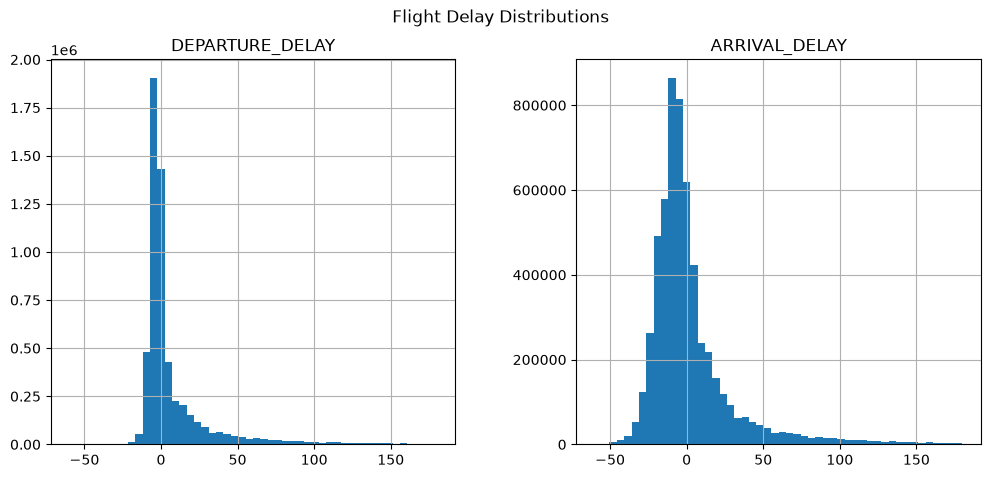

In [26]:
# Plot histograms for departure and arrival delays
flights.hist(
    column=["DEPARTURE_DELAY", "ARRIVAL_DELAY"],
    bins=50,
    figsize=(12, 5),
    range=(-60, 180)
)

# Display the histograms
plt.suptitle("Flight Delay Distributions")
plt.show()

The histograms show that most flights have relatively small departure and arrival delays, while fewer flights experience longer delays. Both distributions are right-skewed, indicating that some flights experience significantly longer delays than the majority.

### 3b. Boxplots — Departure and Arrival Delays

Boxplots are used to compare the spread and central values of departure and arrival delays.

Extreme outliers are hidden in the plots to make the main distributions easier to examine. The original data is not changed.

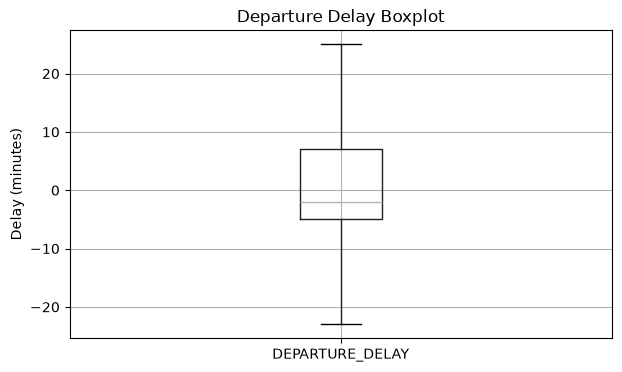

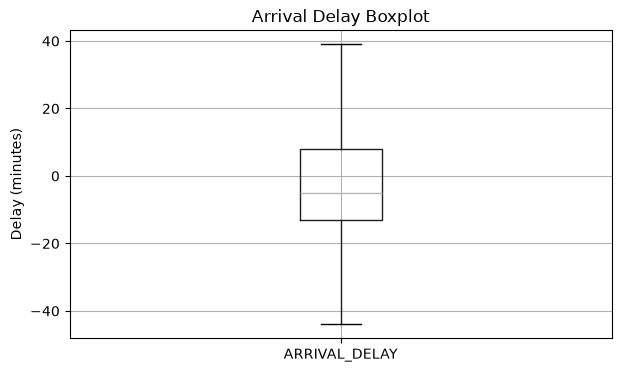

In [27]:
# Plot departure delays
flights.boxplot(
    column="DEPARTURE_DELAY",
    figsize=(7, 4),
    showfliers=False
)

plt.title("Departure Delay Boxplot")
plt.ylabel("Delay (minutes)")
plt.show()

# Plot arrival delays
flights.boxplot(
    column="ARRIVAL_DELAY",
    figsize=(7, 4),
    showfliers=False
)

plt.title("Arrival Delay Boxplot")
plt.ylabel("Delay (minutes)")
plt.show()

The boxplots show the central distribution and variability of departure and arrival delays. The median values and interquartile ranges help compare typical delays and their spread. Extreme values are not displayed because outlier markers have been hidden, allowing the central distributions to be examined more clearly.

### 3c. Scatter Plot — Departure Delay vs. Arrival Delay

A scatter plot is used to examine the relationship between departure and arrival delays.

A random sample of 10,000 records is used to reduce plotting time.

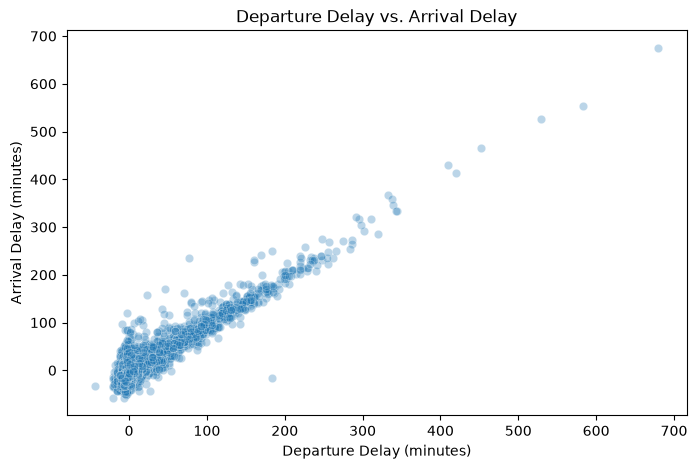

In [28]:
# Select records with valid departure and arrival delays
delay_sample = flights[
    ["DEPARTURE_DELAY", "ARRIVAL_DELAY"]
].dropna().sample(
    n=10000,
    random_state=42
)

# Plot departure delay against arrival delay
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=delay_sample,
    x="DEPARTURE_DELAY",
    y="ARRIVAL_DELAY",
    alpha=0.3
)

plt.title("Departure Delay vs. Arrival Delay")
plt.xlabel("Departure Delay (minutes)")
plt.ylabel("Arrival Delay (minutes)")
plt.show()

The scatter plot shows a strong positive relationship between departure and arrival delays. Flights with longer departure delays generally experience longer arrival delays. However, some flights may recover or accumulate additional delays during the journey.

## 4. Correlation Between Attributes

### 4a. Pearson Correlation Matrix

Pearson correlation is used to measure the linear relationships between selected numerical attributes.

The correlation matrix is displayed as a heatmap to make the relationships easier to compare.

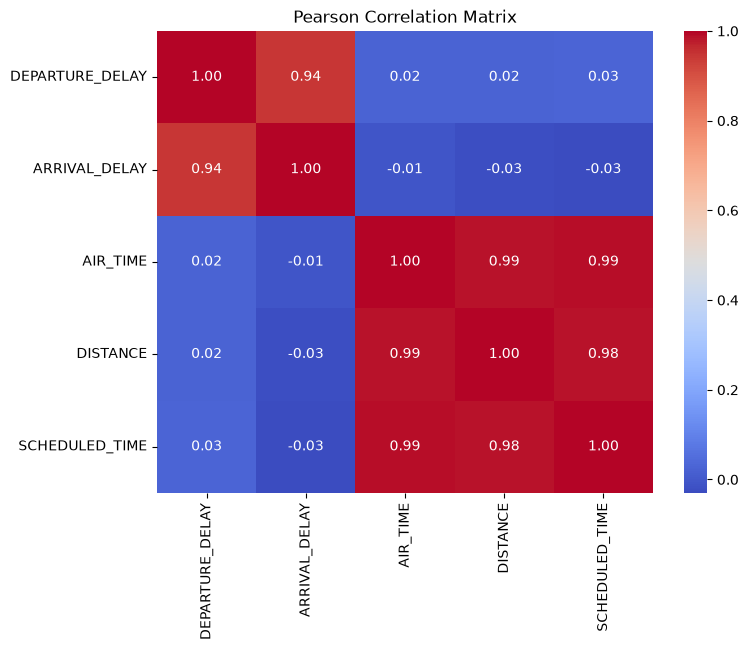

In [29]:
# Select numerical attributes
attributes = [
    "DEPARTURE_DELAY",
    "ARRIVAL_DELAY",
    "AIR_TIME",
    "DISTANCE",
    "SCHEDULED_TIME"
]

# Calculate Pearson correlations
correlation_matrix = flights[attributes].corr()

# Display the correlation matrix
plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Pearson Correlation Matrix")
plt.show()

The correlation matrix shows a very strong positive relationship between departure delay and arrival delay (0.9447), indicating that flights departing late generally tend to arrive late. Air time and distance also have a very strong positive correlation (0.9856). Taxi-out time has a weak positive correlation with arrival delay (0.2273), while distance (-0.0254) and scheduled time (-0.0300) have very weak negative correlations with arrival delay. Correlation measures linear relationships and does not imply causation.

## 5. Data Preprocessing

### 5.1 Data Cleaning

Cancelled flights and records with missing arrival delay values are removed.

These records cannot be assigned a valid arrival-delay classification.

The cleaned dataset is used for feature engineering and model training.

In [30]:
# Remove cancelled flights and records with missing arrival delays
clean_flights = flights.loc[
    (flights["CANCELLED"] == 0) &
    (flights["ARRIVAL_DELAY"].notna())
].copy()

# Check the dataset after cleaning
print("Original dataset:", flights.shape)
print("Cleaned dataset:", clean_flights.shape)

# Confirm that missing arrival delays and cancelled flights were removed
print("\nMissing arrival delays:",
      clean_flights["ARRIVAL_DELAY"].isna().sum())

print("Cancelled flights:",
      clean_flights["CANCELLED"].sum())

Original dataset: (5819079, 31)
Cleaned dataset: (5714008, 31)

Missing arrival delays: 0
Cancelled flights: 0


### 5.2 Target Variable and Class Distribution

A binary target variable named `DELAYED` is created using arrival delay.

- **0:** The flight arrived less than 15 minutes late.
- **1:** The flight arrived 15 minutes late or more.

The target distribution is examined to determine whether the classes are balanced.

In [31]:
# Create the binary target variable
clean_flights["DELAYED"] = (
    clean_flights["ARRIVAL_DELAY"] >= 15
).astype("int8")

# Display the number of flights in each class
print("Target Distribution:")
print(clean_flights["DELAYED"].value_counts())

# Display the percentage of each class
print("\nTarget Percentage:")
print(
    clean_flights["DELAYED"].value_counts(normalize=True) * 100
)

# Check for missing target values
print("\nMissing Target Values:")
print(clean_flights["DELAYED"].isna().sum())

# Check that the target contains only 0 and 1
print("\nTarget Values:")
print(clean_flights["DELAYED"].unique())

Target Distribution:
DELAYED
0    4650569
1    1063439
Name: count, dtype: int64

Target Percentage:
DELAYED
0    81.388913
1    18.611087
Name: proportion, dtype: float64

Missing Target Values:
0

Target Values:
[0 1]


The cleaned dataset contains 5,714,008 flight records.

Of these, 81.39% are not delayed and 18.61% are delayed.

The target distribution is imbalanced, so recall, precision, and F1-score are used alongside accuracy when evaluating the classification models.

### 5.3 Scheduled Time Conversion

Scheduled departure and arrival times are stored in HHMM format.

The values are converted into minutes after midnight to make them easier to use in feature engineering.

In [32]:
# Convert HHMM format into minutes after midnight
def convert_hhmm_to_minutes(time):
    hours = time // 100
    minutes = time % 100
    return hours * 60 + minutes

clean_flights["DEP_MINUTES"] = convert_hhmm_to_minutes(
    clean_flights["SCHEDULED_DEPARTURE"]
)

clean_flights["ARR_MINUTES"] = convert_hhmm_to_minutes(
    clean_flights["SCHEDULED_ARRIVAL"]
)

# Display results
print(
    clean_flights[
        [
            "SCHEDULED_DEPARTURE",
            "DEP_MINUTES",
            "SCHEDULED_ARRIVAL",
            "ARR_MINUTES"
        ]
    ].head()
)

   SCHEDULED_DEPARTURE  DEP_MINUTES  SCHEDULED_ARRIVAL  ARR_MINUTES
0                    5            5                430          270
1                   10           10                750          470
2                   20           20                806          486
3                   20           20                805          485
4                   25           25                320          200


### 5.4 Cyclical Time Features

Scheduled departure and arrival times follow a 24-hour cycle.

Sine and cosine transformations are used to represent this cycle. This prevents times close to midnight from being treated as far apart.

In [33]:
# Create cyclical features for scheduled departure and arrival

for prefix in ["DEP", "ARR"]:
    minutes = clean_flights[f"{prefix}_MINUTES"]

    clean_flights[f"{prefix}_SIN"] = np.sin(
        2 * np.pi * minutes / 1440
    ).astype("float32")

    clean_flights[f"{prefix}_COS"] = np.cos(
        2 * np.pi * minutes / 1440
    ).astype("float32")

# Display the new features
print(
    clean_flights[
        ["DEP_MINUTES", "DEP_SIN", "DEP_COS",
         "ARR_MINUTES", "ARR_SIN", "ARR_COS"]
    ].head()
)

   DEP_MINUTES   DEP_SIN   DEP_COS  ARR_MINUTES   ARR_SIN   ARR_COS
0            5  0.021815  0.999762          270  0.923880  0.382683
1           10  0.043619  0.999048          470  0.887011 -0.461749
2           20  0.087156  0.996195          486  0.852640 -0.522499
3           20  0.087156  0.996195          485  0.854912 -0.518773
4           25  0.108867  0.994056          200  0.766044  0.642788


### 5.5 Feature Selection

The initial feature set includes calendar information, scheduled flight details, airline, and airport information.

Only information available before departure is used.

Actual departure delay, arrival delay, taxi times, and other flight outcomes are excluded to prevent data leakage.

In [34]:
# Numerical features
numeric_features = [
    "MONTH",
    "DAY",
    "DAY_OF_WEEK",
    "SCHEDULED_TIME",
    "DISTANCE",
    "DEP_SIN",
    "DEP_COS",
    "ARR_SIN",
    "ARR_COS"
]

# Categorical features
categorical_features = [
    "AIRLINE",
    "ORIGIN_AIRPORT",
    "DESTINATION_AIRPORT"
]

# Combine selected features
feature_cols = numeric_features + categorical_features

# Create feature and target datasets
X = clean_flights[feature_cols]
y = clean_flights["DELAYED"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

print("\nSelected Features:")
print(X.columns.tolist())

print("\nMissing Values:")
print(X.isna().sum())

Features shape: (5714008, 12)
Target shape: (5714008,)

Selected Features:
['MONTH', 'DAY', 'DAY_OF_WEEK', 'SCHEDULED_TIME', 'DISTANCE', 'DEP_SIN', 'DEP_COS', 'ARR_SIN', 'ARR_COS', 'AIRLINE', 'ORIGIN_AIRPORT', 'DESTINATION_AIRPORT']

Missing Values:
MONTH                  0
DAY                    0
DAY_OF_WEEK            0
SCHEDULED_TIME         0
DISTANCE               0
DEP_SIN                0
DEP_COS                0
ARR_SIN                0
ARR_COS                0
AIRLINE                0
ORIGIN_AIRPORT         0
DESTINATION_AIRPORT    0
dtype: int64


## 6. Train, Validation, and Test Split

The dataset is divided into three subsets:

- **Training set (70%):** Used to train the models.
- **Validation set (15%):** Used to compare experiments and select model settings.
- **Test set (15%):** Used for final evaluation.

Stratified splitting is applied to preserve the target class distribution.

The random state is set to 42 for reproducibility.

In [35]:
from sklearn.model_selection import train_test_split

# First split: 70% training, 30% temporary
X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

# Second split: 15% validation, 15% testing
X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

# Remove temporary references to reduce memory usage
del X_temp, y_temp

print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Testing:", X_test.shape)

print("\nDelayed flight percentage:")
print("Training:", round(y_train.mean() * 100, 2), "%")
print("Validation:", round(y_val.mean() * 100, 2), "%")
print("Testing:", round(y_test.mean() * 100, 2), "%")

Training: (3999805, 12)
Validation: (857101, 12)
Testing: (857102, 12)

Delayed flight percentage:
Training: 18.61 %
Validation: 18.61 %
Testing: 18.61 %


## 7. Data Transformation

Numerical features are standardized using Z-score normalization,
while categorical features are transformed using One-Hot Encoding.

A preprocessing pipeline is used to apply these transformations
consistently. The transformations are fitted on training data
only to prevent data leakage.

In [47]:
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# Create a separate preprocessor for each model
def make_preprocessor(numeric_cols, categorical_cols):

    return ColumnTransformer([
        # Standardize numerical features
        ("num", StandardScaler(), numeric_cols),

        # Encode categorical features
        (
            "cat",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_cols
        )
    ])

print("Preprocessing function created successfully.")

Preprocessing function created successfully.


## 8. Logistic Regression

### 8.1 Baseline Logistic Regression

A baseline Logistic Regression model is trained using a stratified
sample of 500,000 flights from the training dataset.

The preprocessing pipeline applies numerical standardization
and categorical encoding before model training.

The baseline model uses default class weights and a classification
threshold of 0.50. Its performance will be compared with optimized
models using the validation dataset.

In [48]:
from sklearn.linear_model import LogisticRegression

# Select a stratified training sample
X_train_sample, _, y_train_sample, _ = train_test_split(
    X_train,
    y_train,
    train_size=500000,
    random_state=42,
    stratify=y_train
)

# Create baseline Logistic Regression pipeline
baseline_lr = Pipeline([
    ("preprocessing", preprocessor),
    ("classifier", LogisticRegression(
        random_state=42,
        max_iter=1000
    ))
])

# Train the model
baseline_lr.fit(X_train_sample, y_train_sample)

print("Baseline Logistic Regression trained successfully.")
print("Training samples:", len(X_train_sample))

Baseline Logistic Regression trained successfully.
Training samples: 500000


### 8.2 Baseline Model Evaluation

The baseline model is evaluated using the validation set.

Accuracy, precision, recall, F1-score, and the confusion matrix are calculated to measure classification performance.

In [49]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# Evaluate a classification model
def evaluate_model(y_true, predictions):

    print("Accuracy:", round(
        accuracy_score(y_true, predictions), 4
    ))
    print("Precision:", round(
        precision_score(y_true, predictions), 4
    ))
    print("Recall:", round(
        recall_score(y_true, predictions), 4
    ))
    print("F1-score:", round(
        f1_score(y_true, predictions), 4
    ))

    # Display the confusion matrix
    print("\nConfusion Matrix:")
    print(confusion_matrix(y_true, predictions))


# Predict using the validation set
baseline_predictions = baseline_lr.predict(X_val)

# Evaluate the baseline model
evaluate_model(y_val, baseline_predictions)

Accuracy: 0.8139
Precision: 0.526
Recall: 0.001
F1-score: 0.002

Confusion Matrix:
[[697439    146]
 [159354    162]]


The baseline model achieved approximately 81.39% accuracy, but its recall was only 0.10%.

Most flights were predicted as not delayed. As a result, the model failed to identify most delayed flights.

This shows that accuracy alone is not a reliable measure of performance for this imbalanced dataset.

### 8.3 Handling Class Imbalance Using Class Weighting

The dataset contains significantly more non-delayed flights than delayed flights.

The `class_weight="balanced"` setting is used to assign greater weight to the minority class during training.

The balanced model is compared with the baseline model using validation results.

In [50]:
# Create Logistic Regression with balanced class weights
balanced_lr = Pipeline([
    (
        "preprocessing",
        make_preprocessor(numeric_features, categorical_features)
    ),
    (
        "classifier",
        LogisticRegression(
            C=1.0,
            class_weight="balanced",
            random_state=42,
            max_iter=1000
        )
    )
])

# Train the balanced model
balanced_lr.fit(X_train_sample, y_train_sample)

# Evaluate on validation data
balanced_predictions = balanced_lr.predict(X_val)

evaluate_model(y_val, balanced_predictions)

Accuracy: 0.5916
Precision: 0.2562
Recall: 0.6278
F1-score: 0.3639

Confusion Matrix:
[[406932 290653]
 [ 59377 100139]]


Class weighting increased recall to approximately 62.78% and F1-score to 0.3639.

The model identified more delayed flights, but the number of false positives also increased.

The balanced model was used for the remaining experiments.

### 8.4 Classification Threshold Analysis

The classification threshold determines when a predicted probability is classified as delayed.

Different thresholds are tested to examine the tradeoff between precision and recall.

False positives and false negatives are also compared.

In [51]:
# Get predicted delay probabilities
balanced_probabilities = balanced_lr.predict_proba(X_val)[:, 1]

threshold_results = []

# Test thresholds between 0.20 and 0.80
for threshold in np.arange(0.20, 0.81, 0.05):

    # Convert probabilities into class predictions
    predictions = (
        balanced_probabilities >= threshold
    ).astype(int)

    # Calculate confusion matrix values
    tn, fp, fn, tp = confusion_matrix(
        y_val, predictions
    ).ravel()

    # Store evaluation results
    threshold_results.append({
        "Threshold": round(threshold, 2),
        "Precision": precision_score(y_val, predictions),
        "Recall": recall_score(y_val, predictions),
        "F1-score": f1_score(y_val, predictions),
        "False Positives": fp,
        "False Negatives": fn
    })

# Display threshold comparison
threshold_df = pd.DataFrame(threshold_results)

display(threshold_df.round(4))

,Threshold,Precision,Recall,F1-score,False Positives,False Negatives
0,0.20,0.1880,0.9951,0.3162,685629,783
1,0.25,0.1913,0.9837,0.3203,663518,2595
2,0.30,0.1980,0.9572,0.3281,618536,6828
3,0.35,0.2088,0.9084,0.3395,549123,14617
4,0.40,0.2225,0.8363,0.3515,466060,26115
5,0.45,0.2390,0.7424,0.3615,377134,41098
6,0.50,0.2562,0.6278,0.3639,290653,59377
7,0.55,0.2752,0.4939,0.3535,207478,80725
8,0.60,0.2964,0.3324,0.3134,125896,106485
9,0.65,0.3212,0.1699,0.2223,57295,132407


Lower thresholds increased recall but produced more false positives.

Higher thresholds reduced false positives but missed more delayed flights.

The results show that threshold selection depends on the balance required between precision and recall.

### 8.5 Hyperparameter Tuning

The regularization parameter `C` is tested using the values 0.01, 0.1, 1, and 10.

The models are trained using the same training sample and compared using validation F1-score.

In [52]:
# Regularization values to test
c_values = [0.01, 0.1, 1, 10]

tuning_results = []

for c in c_values:

    # Create a separate model for each C value
    model = Pipeline([
        (
            "preprocessing",
            make_preprocessor(numeric_features, categorical_features)
        ),
        (
            "classifier",
            LogisticRegression(
                C=c,
                class_weight="balanced",
                random_state=42,
                max_iter=1000
            )
        )
    ])

    # Train the model
    model.fit(X_train_sample, y_train_sample)

    # Evaluate on validation data
    predictions = model.predict(X_val)

    tuning_results.append({
        "C": c,
        "Precision": precision_score(y_val, predictions),
        "Recall": recall_score(y_val, predictions),
        "F1-score": f1_score(y_val, predictions)
    })

# Display the results
display(pd.DataFrame(tuning_results).round(4))

,C,Precision,Recall,F1-score
0,0.01,0.2557,0.6270,0.3632
1,0.10,0.2563,0.6274,0.3639
2,1.00,0.2562,0.6278,0.3639
3,10.00,0.2560,0.6277,0.3637


The tested regularization values produced similar validation results.

The value `C = 1.0` was retained because changing the regularization strength did not produce a meaningful improvement.

### 8.6 Logistic Regression Coefficient Analysis

The coefficients of the balanced Logistic Regression model are examined to understand how the numerical features contribute to its predictions.

The coefficients are ranked by absolute value.

Because the numerical features are standardized, their coefficients can be compared within this model. However, coefficient size does not necessarily indicate a causal relationship.

In [53]:
# Get the trained Logistic Regression classifier
fitted_classifier = balanced_lr.named_steps["classifier"]

# Extract coefficients for the numerical features
numeric_coefficients = fitted_classifier.coef_[0][
    :len(numeric_features)
]

# Create a coefficient table
feature_importance = pd.DataFrame({
    "Feature": numeric_features,
    "Coefficient": numeric_coefficients,
    "Absolute Coefficient": np.abs(numeric_coefficients)
})

# Sort features by absolute coefficient
feature_importance = feature_importance.sort_values(
    by="Absolute Coefficient",
    ascending=False
)

print(feature_importance.round(4).to_string(index=False))

       Feature  Coefficient  Absolute Coefficient
SCHEDULED_TIME      -0.8494                0.8494
      DISTANCE       0.8056                0.8056
       DEP_SIN      -0.2671                0.2671
       ARR_COS       0.1241                0.1241
         MONTH      -0.0725                0.0725
       ARR_SIN      -0.0684                0.0684
   DAY_OF_WEEK      -0.0327                0.0327
       DEP_COS      -0.0267                0.0267
           DAY      -0.0092                0.0092


### 8.7 Feature Subset Selection

A reduced feature set is tested by removing month, day, and day of week.

The experiment checks whether using fewer features improves Logistic Regression performance.

In [54]:
# Remove calendar variables from the numerical features
numeric_features_reduced = [
    "SCHEDULED_TIME",
    "DISTANCE",
    "DEP_SIN",
    "DEP_COS",
    "ARR_SIN",
    "ARR_COS"
]

reduced_features = (
    numeric_features_reduced + categorical_features
)

# Create the reduced-feature model
reduced_lr = Pipeline([
    (
        "preprocessing",
        make_preprocessor(
            numeric_features_reduced,
            categorical_features
        )
    ),
    (
        "classifier",
        LogisticRegression(
            C=1.0,
            class_weight="balanced",
            random_state=42,
            max_iter=1000
        )
    )
])

# Train using the reduced feature set
reduced_lr.fit(
    X_train_sample[reduced_features],
    y_train_sample
)

# Evaluate on validation data
reduced_predictions = reduced_lr.predict(
    X_val[reduced_features]
)

evaluate_model(y_val, reduced_predictions)

Accuracy: 0.5899
Precision: 0.2553
Recall: 0.6276
F1-score: 0.3629

Confusion Matrix:
[[405518 292067]
 [ 59396 100120]]


The reduced model achieved an F1-score of approximately 0.3629, slightly lower than the balanced model.

Removing the calendar variables did not improve performance.

### 8.8 Time Feature Representation

Two representations of scheduled departure and arrival times are compared:

1. Raw time values in minutes after midnight.
2. Cyclical sine and cosine features.

The experiment checks whether cyclical encoding improves classification performance.

In [55]:
# Create copies for the raw-time experiment
X_train_raw = X_train_sample.copy()
X_val_raw = X_val.copy()

# Add raw scheduled times in minutes
for col in ["DEP_MINUTES", "ARR_MINUTES"]:

    X_train_raw[col] = clean_flights.loc[
        X_train_raw.index, col
    ]

    X_val_raw[col] = clean_flights.loc[
        X_val_raw.index, col
    ]

# Use raw time features instead of sine and cosine
numeric_features_raw = [
    "MONTH",
    "DAY",
    "DAY_OF_WEEK",
    "SCHEDULED_TIME",
    "DISTANCE",
    "DEP_MINUTES",
    "ARR_MINUTES"
]

# Create the raw-time model
raw_lr = Pipeline([
    (
        "preprocessing",
        make_preprocessor(
            numeric_features_raw,
            categorical_features
        )
    ),
    (
        "classifier",
        LogisticRegression(
            C=1.0,
            class_weight="balanced",
            random_state=42,
            max_iter=1000
        )
    )
])

# Train the raw-time model
raw_lr.fit(X_train_raw, y_train_sample)

# Compare both time representations
raw_predictions = raw_lr.predict(X_val_raw)

print("Raw Time Features")
evaluate_model(y_val, raw_predictions)

print("\nCyclical Time Features")
evaluate_model(y_val, balanced_predictions)

Raw Time Features
Accuracy: 0.5981
Precision: 0.2573
Recall: 0.6146
F1-score: 0.3628

Confusion Matrix:
[[414605 282980]
 [ 61475  98041]]

Cyclical Time Features
Accuracy: 0.5916
Precision: 0.2562
Recall: 0.6278
F1-score: 0.3639

Confusion Matrix:
[[406932 290653]
 [ 59377 100139]]


Cyclical time encoding achieved a slightly higher F1-score than the raw-time representation.

Cyclical encoding was retained because it also preserves the relationship between times near midnight.

### 8.9 Calendar Feature Encoding

Month and day of week were initially treated as numerical variables.

In this experiment, they are treated as categorical variables and encoded using One-Hot Encoding.

This allows the model to learn separate effects for different months and weekdays.

In [56]:
# Numerical features
numeric_features_calendar = [
    "DAY",
    "SCHEDULED_TIME",
    "DISTANCE",
    "DEP_SIN",
    "DEP_COS",
    "ARR_SIN",
    "ARR_COS"
]

# Treat month and day of week as categorical features
categorical_features_calendar = [
    "MONTH",
    "DAY_OF_WEEK",
    "AIRLINE",
    "ORIGIN_AIRPORT",
    "DESTINATION_AIRPORT"
]

# Create the calendar-encoding model
calendar_lr = Pipeline([
    (
        "preprocessing",
        make_preprocessor(
            numeric_features_calendar,
            categorical_features_calendar
        )
    ),
    (
        "classifier",
        LogisticRegression(
            C=1.0,
            class_weight="balanced",
            random_state=42,
            max_iter=1000
        )
    )
])

# Train the model
calendar_lr.fit(X_train_sample, y_train_sample)

# Evaluate on validation data
calendar_predictions = calendar_lr.predict(X_val)

evaluate_model(y_val, calendar_predictions)

Accuracy: 0.5999
Precision: 0.2612
Recall: 0.629
F1-score: 0.3691

Confusion Matrix:
[[413813 283772]
 [ 59183 100333]]


Calendar encoding improved the validation F1-score from approximately 0.3639 to 0.3691.

Treating month and day of week as categorical variables produced better results than the initial numerical representation.

### 8.10 Route Feature Engineering

A route feature is created by combining the origin and destination airports.

This experiment checks whether representing each route as a separate categorical value improves prediction performance.

In [57]:
# Create copies for the route experiment
X_train_route = X_train_sample.copy()
X_val_route = X_val.copy()

# Combine origin and destination airports
for data in [X_train_route, X_val_route]:

    data["ROUTE"] = (
        data["ORIGIN_AIRPORT"].astype(str)
        + "_"
        + data["DESTINATION_AIRPORT"].astype(str)
    )

# Add ROUTE to the categorical features
categorical_features_route = (
    categorical_features_calendar + ["ROUTE"]
)

# Create the route model
route_lr = Pipeline([
    (
        "preprocessing",
        make_preprocessor(
            numeric_features_calendar,
            categorical_features_route
        )
    ),
    (
        "classifier",
        LogisticRegression(
            C=1.0,
            class_weight="balanced",
            random_state=42,
            max_iter=1000
        )
    )
])

# Train the route model
route_lr.fit(X_train_route, y_train_sample)

# Evaluate on validation data
route_predictions = route_lr.predict(X_val_route)

evaluate_model(y_val, route_predictions)

Accuracy: 0.6026
Precision: 0.2611
Recall: 0.6203
F1-score: 0.3675

Confusion Matrix:
[[417559 280026]
 [ 60561  98955]]


The route model achieved a validation F1-score of approximately 0.3675, lower than the calendar-encoding model.

The route feature was not included in the selected configuration.

### 8.11 Airline and Departure Period Interaction

A new categorical feature is created by combining the airline with the scheduled departure period.

The day is divided into four periods:

- Night: 00:00–05:59
- Morning: 06:00–11:59
- Afternoon: 12:00–17:59
- Evening: 18:00–23:59

The interaction feature allows the model to represent different departure-time patterns for each airline.

In [58]:
# Create a function to add departure-period features
def add_interaction_feature(data):

    data = data.copy()

    # Retrieve scheduled departure time
    dep_minutes = clean_flights.loc[
        data.index, "DEP_MINUTES"
    ]

    # Convert minutes into hours
    dep_hour = (dep_minutes // 60) % 24

    # Assign each flight to a departure period
    data["DEP_PERIOD"] = pd.cut(
        dep_hour,
        bins=[-1, 5, 11, 17, 23],
        labels=[
            "Night",
            "Morning",
            "Afternoon",
            "Evening"
        ]
    ).astype(str)

    # Combine airline and departure period
    data["AIRLINE_DEP_PERIOD"] = (
        data["AIRLINE"].astype(str)
        + "_"
        + data["DEP_PERIOD"]
    )

    return data


# Add the interaction feature to training and validation data
X_train_interaction = add_interaction_feature(
    X_train_sample
)

X_val_interaction = add_interaction_feature(
    X_val
)

In [59]:
# Include the interaction feature
categorical_features_interaction = (
    categorical_features_calendar
    + ["AIRLINE_DEP_PERIOD"]
)

# Create the interaction model
interaction_lr = Pipeline([
    (
        "preprocessing",
        make_preprocessor(
            numeric_features_calendar,
            categorical_features_interaction
        )
    ),
    (
        "classifier",
        LogisticRegression(
            C=1.0,
            class_weight="balanced",
            random_state=42,
            max_iter=1000
        )
    )
])

# Train the interaction model
interaction_lr.fit(
    X_train_interaction,
    y_train_sample
)

# Evaluate on validation data
interaction_predictions = interaction_lr.predict(
    X_val_interaction
)

evaluate_model(y_val, interaction_predictions)

Accuracy: 0.5974
Precision: 0.2617
Recall: 0.6387
F1-score: 0.3712

Confusion Matrix:
[[410125 287460]
 [ 57641 101875]]


The interaction model achieved a validation F1-score of approximately 0.3712 and recall of 63.87%.

It identified more delayed flights than the calendar-only model, but also produced more false positives at the default threshold.

### 8.12 Model Comparison

The Logistic Regression experiments are compared using accuracy, precision, recall, and F1-score.

All results in this comparison are calculated using the validation dataset.

The comparison is used to select the feature configuration for the final model.

In [60]:
# Collect validation predictions from each experiment
experiments = {
    "Baseline": baseline_predictions,
    "Balanced": balanced_predictions,
    "Reduced Features": reduced_predictions,
    "Raw Time": raw_predictions,
    "Calendar Encoding": calendar_predictions,
    "Calendar + Route": route_predictions,
    "Calendar + Interaction": interaction_predictions
}

comparison_results = []

# Calculate evaluation metrics for each model
for name, predictions in experiments.items():

    comparison_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_val, predictions),
        "Precision": precision_score(y_val, predictions),
        "Recall": recall_score(y_val, predictions),
        "F1-score": f1_score(y_val, predictions)
    })

# Sort models by validation F1-score
comparison_df = pd.DataFrame(comparison_results)

display(
    comparison_df.sort_values(
        "F1-score",
        ascending=False
    ).round(4)
)

,Model,Accuracy,Precision,Recall,F1-score
6,Calendar + Interaction,0.5974,0.2617,0.6387,0.3712
4,Calendar Encoding,0.5999,0.2612,0.6290,0.3691
5,Calendar + Route,0.6026,0.2611,0.6203,0.3675
1,Balanced,0.5916,0.2562,0.6278,0.3639
2,Reduced Features,0.5899,0.2553,0.6276,0.3629
3,Raw Time,0.5981,0.2573,0.6146,0.3628
0,Baseline,0.8139,0.5260,0.0010,0.0020


### 8.13 False Positive Comparison

The calendar-encoding and interaction models are compared using their confusion matrices.

False positives represent flights predicted as delayed when they were not delayed.

This comparison examines the effect of the interaction feature on false-positive and false-negative predictions.

In [61]:
# Compare confusion matrices for both models
for name, predictions in [
    ("Calendar Encoding", calendar_predictions),
    ("Calendar + Interaction", interaction_predictions)
]:

    # Calculate confusion matrix values
    tn, fp, fn, tp = confusion_matrix(
        y_val, predictions
    ).ravel()

    print(f"\n{name}")
    print("-" * 35)

    print("True Negatives:", tn)
    print("False Positives:", fp)
    print("False Negatives:", fn)
    print("True Positives:", tp)


Calendar Encoding
-----------------------------------
True Negatives: 413813
False Positives: 283772
False Negatives: 59183
True Positives: 100333

Calendar + Interaction
-----------------------------------
True Negatives: 410125
False Positives: 287460
False Negatives: 57641
True Positives: 101875


At the default threshold of 0.50, the interaction model identified 1,542 additional delayed flights compared with the calendar-only model.

However, it also produced 3,688 additional false positives.

Threshold adjustment was examined to compare the models at a similar recall level.

### 8.14 Matched-Recall Threshold Comparison

The interaction model is evaluated at approximately the same recall as the calendar-encoding model.

This allows the false-positive counts to be compared while maintaining a similar level of delayed-flight detection.

In [62]:
from sklearn.metrics import precision_recall_curve

# Get predicted probabilities from the interaction model
interaction_probabilities = interaction_lr.predict_proba(
    X_val_interaction
)[:, 1]

# Calculate precision and recall at different thresholds
precision, recall, thresholds = precision_recall_curve(
    y_val,
    interaction_probabilities
)

# Use the calendar model's recall as the target
target_recall = recall_score(
    y_val,
    calendar_predictions
)

# Find the threshold with the closest recall
matched_idx = np.argmin(
    np.abs(recall[:-1] - target_recall)
)

matched_threshold = thresholds[matched_idx]

# Generate predictions at the matched threshold
matched_predictions = (
    interaction_probabilities >= matched_threshold
).astype(int)

# Calculate confusion matrix values
tn, fp, fn, tp = confusion_matrix(
    y_val,
    matched_predictions
).ravel()

# Display results
print("Interaction threshold:", round(matched_threshold, 4))
print("Target recall:", round(target_recall, 4))
print("Matched recall:", round(
    recall_score(y_val, matched_predictions), 4
))
print("Precision:", round(
    precision_score(y_val, matched_predictions), 4
))
print("F1-score:", round(
    f1_score(y_val, matched_predictions), 4
))
print("False positives:", fp)
print("False negatives:", fn)

Interaction threshold: 0.504
Target recall: 0.629
Matched recall: 0.629
Precision: 0.2631
F1-score: 0.371
False positives: 280988
False negatives: 59183


At a threshold of approximately 0.504, the interaction model achieved the same recall as the calendar-only model, approximately 62.90%.

False positives decreased from 283,772 to 280,988, a reduction of 2,784 incorrect delay predictions.

The interaction model also achieved a higher F1-score of 0.3710 compared with 0.3691 for the calendar-only model.

### 8.15 Threshold Optimization

The interaction model's classification threshold is optimized using validation data.

Precision and recall are calculated across the available thresholds, and the threshold with the highest F1-score is selected.

In [63]:
# Calculate F1-score for each classification threshold
f1_scores = (
    2 * precision[:-1] * recall[:-1]
    / (precision[:-1] + recall[:-1] + 1e-10)
)

# Find the threshold with the highest F1-score
best_idx = np.argmax(f1_scores)

best_threshold = thresholds[best_idx]

# Display the selected threshold and metrics
print("Best threshold:", round(best_threshold, 4))
print("Best precision:", round(precision[best_idx], 4))
print("Best recall:", round(recall[best_idx], 4))
print("Best F1-score:", round(f1_scores[best_idx], 4))

Best threshold: 0.5001
Best precision: 0.2617
Best recall: 0.6384
Best F1-score: 0.3713


The highest validation F1-score was 0.3713 at a threshold of approximately 0.5001.

At this threshold, precision was 26.17% and recall was 63.84%.

This threshold was selected for the final Logistic Regression configuration.

### 8.16 Precision–Recall Curve

The precision–recall curve shows the relationship between precision and recall across classification thresholds.

Average Precision (AP) is used to summarize the model's ability to rank delayed flights above non-delayed flights.

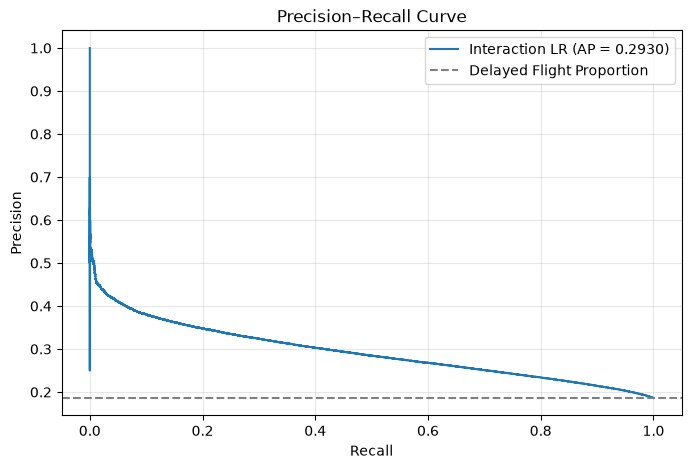

In [64]:
from sklearn.metrics import average_precision_score

# Calculate Average Precision
average_precision = average_precision_score(
    y_val,
    interaction_probabilities
)

# Plot precision against recall
plt.figure(figsize=(8, 5))

plt.plot(
    recall,
    precision,
    label=f"Interaction LR (AP = {average_precision:.4f})"
)

# Show the proportion of delayed flights
plt.axhline(
    y=y_val.mean(),
    linestyle="--",
    color="gray",
    label="Delayed Flight Proportion"
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision–Recall Curve")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## 9. Final Logistic Regression Model

The interaction-enhanced Logistic Regression model was selected based on validation F1-score.

The selected configuration uses:

- Balanced class weights.
- Regularization parameter C = 1.0.
- Standardization of numerical features.
- One-Hot Encoding of categorical features.
- Cyclical scheduled-time features.
- Categorical month and day-of-week features.
- Airline–departure period interaction.
- Classification threshold of approximately 0.5001.

The model is retrained using the combined training and validation datasets before test evaluation.

In [65]:
# Combine training and validation data
X_final_train = pd.concat(
    [X_train, X_val],
    axis=0
)

y_final_train = pd.concat(
    [y_train, y_val],
    axis=0
)

# Add the interaction feature to the final training data
X_final_interaction = add_interaction_feature(
    X_final_train
)

# Prepare the test data using the same feature engineering
X_test_interaction = add_interaction_feature(
    X_test
)

# Create the selected Logistic Regression model
final_interaction_lr = Pipeline([
    (
        "preprocessing",
        make_preprocessor(
            numeric_features_calendar,
            categorical_features_interaction
        )
    ),
    (
        "classifier",
        LogisticRegression(
            C=1.0,
            class_weight="balanced",
            random_state=42,
            max_iter=1000
        )
    )
])

# Train on the combined training and validation sets
final_interaction_lr.fit(
    X_final_interaction,
    y_final_train
)

print("Final Logistic Regression training completed.")
print("Training records:", len(X_final_train))

Final Logistic Regression training completed.
Training records: 4856906


## 10. Final Model Evaluation

The selected Logistic Regression model is evaluated using the designated test dataset.

Accuracy, precision, recall, F1-score, and the confusion matrix are calculated.

The classification threshold was selected using validation data before final model training.

An earlier Logistic Regression configuration had already been evaluated on this test set during development. Therefore, the test results are not a completely independent assessment of the overall model-selection process.

In [66]:
# Get predicted delay probabilities for the test set
final_probabilities = final_interaction_lr.predict_proba(
    X_test_interaction
)[:, 1]

# Apply the selected classification threshold
final_predictions = (
    final_probabilities >= best_threshold
).astype(int)

# Evaluate the final model
print("Final Logistic Regression Test Results")
print("-" * 40)

evaluate_model(y_test, final_predictions)

# Display classification metrics for both classes
print("\nClassification Report:")
print(
    classification_report(
        y_test,
        final_predictions,
        target_names=["Not Delayed", "Delayed"]
    )
)

Final Logistic Regression Test Results
----------------------------------------
Accuracy: 0.599
Precision: 0.2635
Recall: 0.6433
F1-score: 0.3739

Confusion Matrix:
[[410812 286774]
 [ 56899 102617]]

Classification Report:
              precision    recall  f1-score   support

 Not Delayed       0.88      0.59      0.71    697586
     Delayed       0.26      0.64      0.37    159516

    accuracy                           0.60    857102
   macro avg       0.57      0.62      0.54    857102
weighted avg       0.76      0.60      0.64    857102



### 10.1 Confusion Matrix Visualization

The confusion matrix shows the number of correct and incorrect predictions for delayed and non-delayed flights.

It is used to examine false positives and false negatives in the final test results.

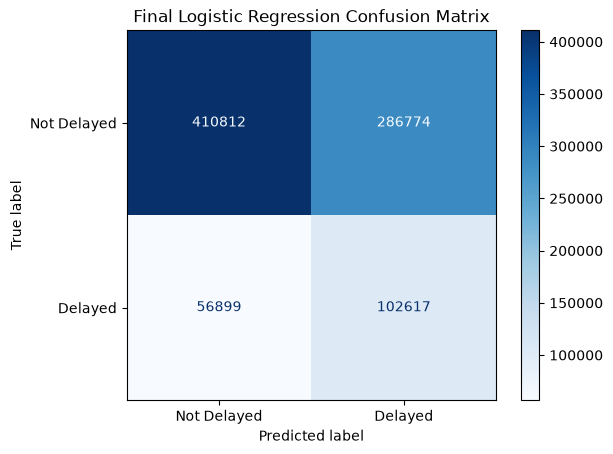

In [67]:
from sklearn.metrics import ConfusionMatrixDisplay

# Display the final test confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_test,
    final_predictions,
    display_labels=["Not Delayed", "Delayed"],
    cmap="Blues",
    values_format="d"
)

plt.title("Final Logistic Regression Confusion Matrix")
plt.show()

## 11. Logistic Regression Conclusion

Logistic Regression was used to predict flight arrival delays using scheduled flight information.

The baseline model achieved high accuracy but very low recall because the dataset contains significantly more non-delayed flights than delayed flights.

Applying balanced class weights improved recall and F1-score, although it also increased false-positive predictions.

Several experiments were conducted to improve performance, including regularization tuning, feature subset selection, time representation, calendar encoding, route information, and an airline–departure period interaction.

Calendar encoding improved the validation F1-score to 0.3691. Adding the airline–departure period interaction increased the score to approximately 0.3712 at the default threshold.

Threshold optimization produced the highest validation F1-score of 0.3713 at a threshold of approximately 0.5001.

At approximately equal recall, the interaction model also reduced false positives by 2,784 compared with the calendar-only model.

Although the improvements were modest, the experiments showed that feature representation and threshold selection affect Logistic Regression performance.

Precision remained relatively low, indicating that many non-delayed flights were incorrectly predicted as delayed.

The selected model was retrained using the combined training and validation data. Its final test results are reported separately from the validation experiments.

Logistic Regression provides a baseline for comparison with the Decision Tree and Random Forest models.